[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wellingtonmnf/pos-graduacao-ia-ciencia-dados/blob/main/disciplinas/aprendizado-de-maquina/notebooks/unidade-02-classificacao/algoritmo-arvore-de-decisao.ipynb)

###A Analogia da Planta Baixa

Antes de mergulhar no código, pense assim: um arquiteto analisa as características de um terreno (área, topografia, orientação solar) para decidir que tipo de edificação é mais adequada. Uma Árvore de Decisão faz exatamente isso, só que com dados: ela aprende a fazer perguntas encadeadas sobre as características de um objeto para chegar a uma conclusão (classificação).


1. Importando as ferramentas

In [57]:
#importando as bibliotecas
from sklearn.datasets import load_iris # base de dados famosa para aprendizado
from sklearn.model_selection import train_test_split # ferramenta de divisão de dados
#importando o modelo árvore de decisão
from sklearn.tree import DecisionTreeClassifier # o algoritmo principal

O `sklearn` (scikit-learn) é uma biblioteca de machine learning — pense nela como uma "caixa de ferramentas" já montada. Você não precisa construir os algoritmos do zero, apenas utilizá-los.

2. Carregando os dados

In [58]:
#carregando os dados
X, y = load_iris(return_X_y=True)

O dataset Iris é um conjunto de dados com medições de 150 flores de íris — comprimento e largura de pétalas e sépalas. Aqui, `X` representa as **características** (as medidas das flores) e `y` representa o **rótulo** (qual das 3 espécies de íris cada flor pertence). É como se `X` fosse a planta baixa e `y` fosse o "gabarito" do tipo de edificação que ela representa.

3. Dividindo os dados em treino e teste

In [59]:
#separando a base de treino da validação
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0)

Este é um passo **fundamental**. Você divide seus dados em dois grupos: metade para **ensinar** o modelo (`train`) e metade para **avaliar** se ele aprendeu de verdade (`test`). O parâmetro `test_size=0.5 `significa exatamente isso: 50% para cada grupo. O `random_state=0` garante que a divisão seja sempre a mesma — isso é importante para que seus experimentos sejam reproduzíveis.

> 💡 Pense assim: é como criar um gabarito de um projeto e depois escondê-lo do estudante durante o aprendizado. Depois você usa o gabarito para medir o desempenho dele.



4. Criando e treinando o classificador

In [60]:
#criando o classificador
dtc = DecisionTreeClassifier() # instancia o modelo (ainda "em branco")
#treinando o classificador
dtc.fit(X_train, y_train) # o modelo aprende com os dados de treino

DecisionTreeClassifier()

O `.fit() `é onde a magia acontece. O algoritmo analisa os dados de treino e constrói internamente uma árvore de perguntas do tipo *"o comprimento da pétala é menor que 2.5cm? Se sim, é a espécie A. Se não, faça outra pergunta..."*

5. Fazendo previsões

In [61]:
#realizando as previsões
y_pred = dtc.predict(X_test)

Agora você apresenta ao modelo os dados que ele **nunca viu** (`X_test`) e pede que ele classifique cada flor. O resultado fica em `y_pred`.

### Como Ver os Resultados? 📊

Aqui está o complemento natural do código. Vamos avaliar o quão bem o modelo aprendeu:

Acurácia: 0.96

Relatório de Classificação:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        21
  versicolor       0.94      0.97      0.95        30
   virginica       0.96      0.92      0.94        24

    accuracy                           0.96        75
   macro avg       0.96      0.96      0.96        75
weighted avg       0.96      0.96      0.96        75



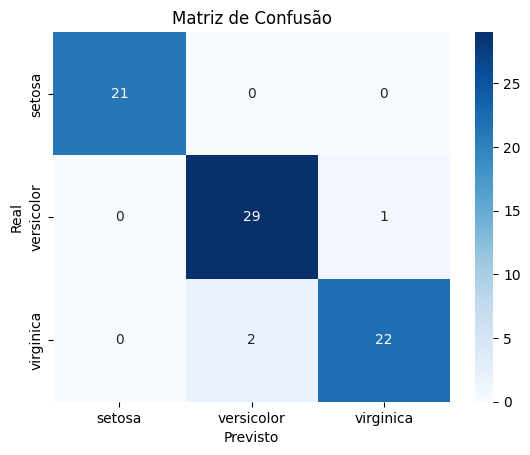

In [62]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Acurácia geral — percentual de acertos
print("Acurácia:", accuracy_score(y_test, y_pred))

# 2. Relatório completo por classe — precisão, recall e F1-score
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred,
      target_names=['setosa', 'versicolor', 'virginica']))

# 3. Matriz de confusão — mostra onde o modelo errou
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["setosa", "versicolor", "virginica"],
            yticklabels=["setosa", "versicolor", "virginica"])
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.title("Matriz de Confusão")
plt.show()

A **acurácia** te diz, em percentual, quantas flores foram classificadas corretamente. O **relatório de classificação** vai mais fundo, mostrando o desempenho para cada espécie individualmente. A **matriz de confusão** é especialmente interessante: ela revela *com quais espécies o modelo se confunde*, ou seja, onde estão os erros.

Vamos visualizar a árvore de decisão em si — ver graficamente as perguntas que o modelo faz:

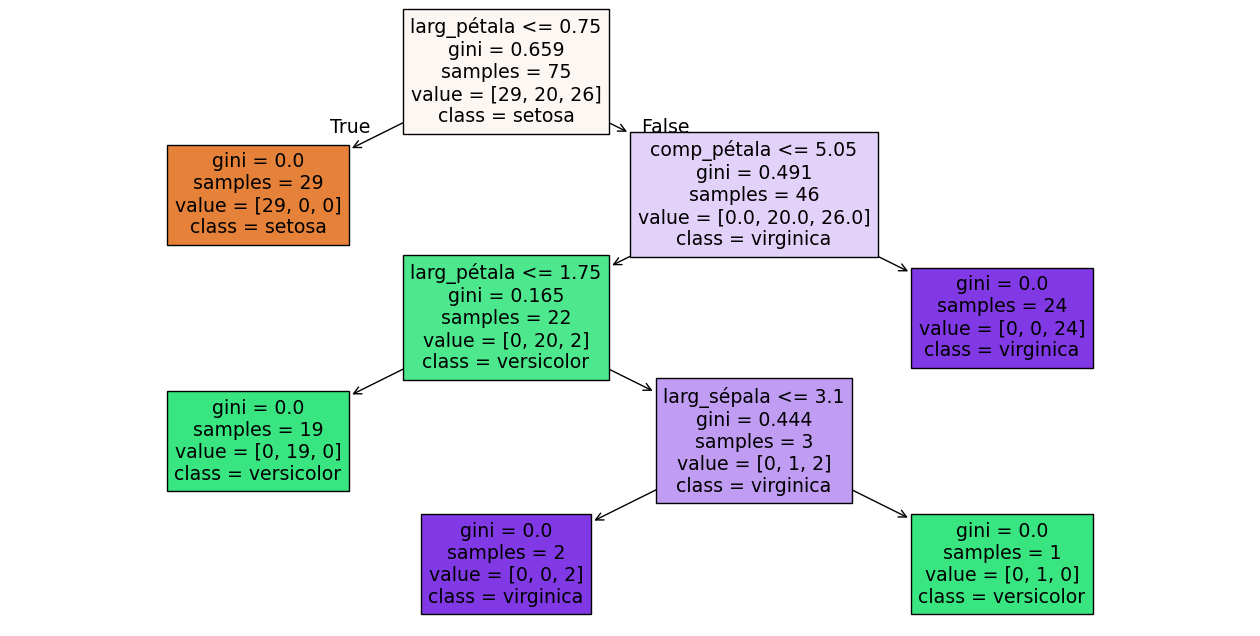

In [63]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 8))
plot_tree(dtc,
          feature_names=['comp_sépala', 'larg_sépala', 'comp_pétala', 'larg_pétala'],
          class_names=['setosa', 'versicolor', 'virginica'],
          filled=True)  # colore os nós por classe
plt.show()

Isso vai gerar um diagrama visual da árvore, que é uma das grandes vantagens deste algoritmo: ele é **interpretável** — diferente de redes neurais, você consegue ver exatamente como ele tomou cada decisão.

### Explicação sobre números divergentes nos resultados dos gráficos

Os dois gráficos estão mostrando populações de dados completamente diferentes. Eles não deveriam ter os mesmos números — e está tudo correto!

**O Que Cada Gráfico Realmente Mostra**

🌳 A Árvore de Decisão → Retrato do Aprendizado (dados de treino)
Cada nó da árvore descreve como as **75 flores de treino** foram organizadas durante o aprendizado. Quando você vê no nó raiz:


```
samples = 75
value = [29, 20, 26]
```

Isso significa: "*Das 75 flores que usei para aprender, 29 eram setosa, 20 eram versicolor e 26 eram virginica.*"
O nó laranja com `samples = 29, class = setosa` diz: "*Após a primeira pergunta (`comp_pétala <= 2.35`), todas as 29 setosas do treino foram separadas perfeitamente.*"

> 💡 A árvore é o "caderno de estudos" do modelo — ela registra o que ele aprendeu e como organizou esse conhecimento a partir dos dados de treino.






📊 **A Matriz de Confusão → Retrato do Desempenho (dados de teste)**

A matriz mostra o que aconteceu quando o modelo tentou classificar as **75 flores de teste** — flores que ele nunca tinha visto antes.

```
Setosa:      21 acertos, 0 erros  ✅
Versicolor:  29 acertos, 1 erro   ✅ (1 classificada como virginica)
Virginica:   22 acertos, 2 erros  ✅ (2 classificadas como versicolor)
```

O total bate: 21 + 29 + 22 + 1 + 2 = **75 amostras de teste.** ✔️

> 💡 A matriz é o "**gabarito corrigido**" — ela mostra o desempenho do modelo diante de dados novos.




**O Resumo Visual da Situação**

```
150 flores (dataset completo)
        │
        ├──── 75 flores de TREINO ──→ 🌳 Árvore de Decisão
        │         (o modelo aprende)       (mostra como aprendeu)
        │
        └──── 75 flores de TESTE  ──→ 📊 Matriz de Confusão
                  (o modelo é avaliado)    (mostra o desempenho)
```

As 29 setosas da árvore estavam no **treino**. As 21 setosas da matriz estavam no **teste**. Por acaso, a divisão aleatória com `random_state=0` colocou 29 setosas no treino e 21 no teste — o que é perfeitamente normal.


## Precisão e recall na execução histórica

A matriz descrita acima e o relatório de classificação preservado correspondem à execução histórica. Os percentuais por classe são:

| Espécie | Precisão | Recall | Acertos / exemplos reais |
| --- | --- | --- | --- |
| Setosa | 100% | 100% | 21 / 21 |
| Versicolor | 93,55% | 96,67% | 29 / 30 |
| Virginica | 95,65% | 91,67% | 22 / 24 |

Precisão = TP / (TP + FP): entre as previsões de uma espécie, quantas estavam corretas. Recall = TP / (TP + FN): entre os exemplos reais daquela espécie, quantos foram encontrados. TP são verdadeiros positivos, FP falsos positivos e FN falsos negativos, considerando cada espécie contra as demais.

A acurácia histórica foi de 72 / 75 = 96%. O relatório impresso arredonda as métricas para duas casas decimais. Uma nova execução pode produzir valores diferentes.

O nó de setosa com gini = 0 é puro nos dados de treino. Já os 100% de precisão e recall de setosa no teste vêm das previsões de teste; a pureza de um nó no treino não garante esse desempenho em dados novos.

As saídas históricas não foram recalculadas nesta manutenção.

### Um Exercício para Fixar

Tente rodar o código e depois experimente mudar o `test_size` para `0.2` (20% para teste, 80% para treino). Observe se a acurácia muda. O que você acha que acontece quando o modelo tem mais dados para aprender? Isso vai te dar uma intuição importante sobre a relação entre tamanho dos dados de treino e desempenho do modelo — um dos temas centrais da ementa!